# UniGuide — Topic 4: Data Quality and Responsible Data Practices
Run in Colab. Restore the existing `/content/week3_project` folder first (including Topic 3 JSONL, manifest, raw PDFs and docs). Do not overwrite Topic 3 outputs. Complete manual review cells before exporting. No model API key is needed.

## A0 — Plan the Quality Gate

### Project: UniGuide

UniGuide is an AI-powered academic information assistant designed for UTM undergraduate students. The purpose of this quality gate is to ensure that the prepared academic documents are sufficiently reliable, accurate and relevant before proceeding to retrieval and answer generation.

The following table connects the Topic 2 system requirements with the Topic 4 data quality checks.

| Requirement ID | Requirement | Data Quality Dimension | Quality Check | Proposed Acceptance Criteria |
|---|---|---|---|---|
| FR1, FR2 | Provide academic information and course registration guidance | Completeness | Source and page coverage analysis | All three selected academic sources are represented. |
| FR3 | Provide official source references | Consistency | Source and page metadata validation | 100% of retained chunks have valid source and page references. |
| FR4 | Identify insufficient information | Completeness | Identify missing information and coverage limitations | Known information gaps are documented. |
| FR5 | Present clear academic information | Accuracy | Manual inspection and text validation | Unreadable and misleading text is excluded pending correction. |
| NFR2 | Generate factually correct answers | Accuracy | Manual inspection and Pandera validation | No unresolved hard validation failures in the cleaned dataset. |
| NFR4 | Support academic document updates | Timeliness | Review document editions and academic sessions | Document versions and verification status are documented. |
| RAI1 | Prevent hallucination and misinformation | Accuracy and consistency | Metadata validation and corrupted text review | Retained chunks are traceable to their original documents. |
| RAI2 | Identify out-of-scope enquiries | Completeness | Review source scope and representation | Knowledge domain limitations are documented. |
| RAI3 | Protect student personal information | Privacy and governance | Inspect documents for personal information | No known unnecessary student personal information in the retrieval dataset. |
| FR1, NFR2 | Support reliable academic retrieval | Uniqueness | SHA-256 duplicate detection | All detected duplicate groups are reviewed. |

### Quality Gate Decision Criteria

- **GO:** All mandatory data quality checks are satisfied, with no unresolved significant risks.
- **GO WITH CONDITIONS:** The cleaned dataset is suitable for further development, but identified limitations require mitigation or additional verification.
- **HOLD:** Critical data quality, privacy or source reliability issues remain unresolved.

The quality gate focuses on dataset readiness. System-level requirements such as answer correctness, response latency, citation correctness and refusal accuracy will be evaluated during later system testing.

In [3]:
from pathlib import Path

path = Path("/content/week3_project/docs/week2_requirements.md")

if path.exists():
    print(path.read_text(encoding="utf-8"))
else:
    print("Requirements file not found.")
    print("Available files:")
    for file in path.parent.glob("*"):
        print(file.name)

Requirements file not found.
Available files:
week4_data_quality_report.md


In [35]:
from google.colab import files
from pathlib import Path

uploaded = files.upload()

docs_dir = Path("/content/week3_project/docs")
docs_dir.mkdir(parents=True, exist_ok=True)

for filename, content in uploaded.items():
    target = docs_dir / "week2_requirements.md"
    target.write_bytes(content)
    print(f"Successfully saved: {target}")

Saving week2_requirements.md to week2_requirements.md
Successfully saved: /content/week3_project/docs/week2_requirements.md


## A1 — Load and verify Topic 3 hand-off

In [5]:
!pip -q install pandera pandas matplotlib langchain-core pypdf

**Upload your Week 3 files**

In [6]:
from google.colab import files
import zipfile

uploaded = files.upload()

with zipfile.ZipFile("week3_project.zip", "r") as zip_ref:
    zip_ref.extractall("/content/week3_project")

print("Week 3 project successfully restored.")

Saving week3_project.zip to week3_project (1).zip
Week 3 project successfully restored.


**Verify the files**

In [7]:
import os

path = "/content/week3_project/data/pipeline_v1/documents"

print(os.listdir(path))

['pipeline_manifest.json', 'prepared_text.jsonl']


In [8]:
from pathlib import Path
import json, pickle, re, hashlib
import pandas as pd
import matplotlib.pyplot as plt
import pandera.pandas as pa
from langchain_core.documents import Document
from pypdf import PdfReader
from IPython.display import display
BASE = Path('/content/week3_project')
DATA = BASE / 'data'
DOCS = BASE / 'docs'
RAW = DATA / 'raw'
DOCS.mkdir(parents=True, exist_ok=True)
INPUT = DATA / 'pipeline_v1/documents/prepared_text.jsonl'
MANIFEST = INPUT.parent / 'pipeline_manifest.json'
assert INPUT.is_file() and MANIFEST.is_file(), 'Restore Topic 3 outputs first.'
records = [json.loads(line) for line in INPUT.read_text(encoding='utf-8').splitlines() if line.strip()]
manifest = json.loads(MANIFEST.read_text(encoding='utf-8'))
assert records, 'Empty corpus'
validation = manifest['validation']
assert validation['record_count'] == len(records)
assert hashlib.sha256(INPUT.read_bytes()).hexdigest() in validation['output_sha256']
# Adapt the actual Topic 3 schema to the lecturer's Document format.
chunks = [Document(page_content=r['text'], metadata={k:v for k,v in r.items() if k != 'text'}) for r in records]
prepared_records = [{'chunk_id':r['id'], 'text':r['text'], 'metadata':c.metadata} for r,c in zip(records,chunks)]
with (DATA/'prepared_chunks.jsonl').open('w',encoding='utf-8') as f:
    for r in prepared_records: f.write(json.dumps(r,ensure_ascii=False)+'\n')
with (DATA/'chunks.pkl').open('wb') as f: pickle.dump(chunks,f)
# Reload only the pickle created locally above, never an untrusted pickle.
with (DATA/'chunks.pkl').open('rb') as f: chunks=pickle.load(f)
prepared_records=[json.loads(s) for s in (DATA/'prepared_chunks.jsonl').read_text(encoding='utf-8').splitlines()]
assert len(chunks)==len(prepared_records)
assert all(c.page_content==r['text'] and c.metadata==r['metadata'] for c,r in zip(chunks,prepared_records))
print('Verified records:',len(chunks)); print(chunks[0].metadata)

Verified records: 285
{'id': 1, 'source_id': 'S01', 'source': 'academic_regulations_2026.pdf', 'page': 1}


## A2 — Build a quality inventory (lecturer Cell 2, adapted)

In [9]:
source_files={'S01':'academic_regulations_2026.pdf','S02':'course_registration_guide_2026_2027.pdf','S03':'academic_calendar_2026_2027.pdf'}
page_counts={sid:len(PdfReader(str(RAW/name)).pages) for sid,name in source_files.items() if (RAW/name).is_file()}
assert len(page_counts)==3, 'Restore all three raw PDFs for page validation.'
rows=[]
for chunk in chunks:
    text=chunk.page_content or ''
    meta=chunk.metadata
    sid=meta.get('source_id'); page=meta.get('page'); source=meta.get('source','') or ''
    rows.append(dict(chunk_id=meta['id'],source_id=sid,source=source,page=page,text=text,char_count=len(text.strip()),missing_text=not bool(text.strip()),missing_source=not bool(source.strip()),corrupted_char=('\x00' in text or '�' in text),noisy_whitespace=bool(re.search(r'\n{4,}| {4,}',text)),gid_error=bool(re.search(r'/gid\d+',text)),valid_reference=(sid in source_files and source==source_files.get(sid) and type(page) is int and 1<=page<=page_counts.get(sid,0))))
df=pd.DataFrame(rows)
display(df.drop(columns='text').head())
print(df.char_count.describe())
print(df[['missing_text','missing_source','corrupted_char','noisy_whitespace','gid_error']].sum())

,chunk_id,source_id,source,page,char_count,missing_text,missing_source,corrupted_char,noisy_whitespace,gid_error,valid_reference
0,1,S01,academic_regulations_2026.pdf,1,465,False,False,False,False,False,True
1,2,S01,academic_regulations_2026.pdf,2,75,False,False,False,False,False,True
2,3,S01,academic_regulations_2026.pdf,4,219,False,False,False,False,False,True
3,4,S01,academic_regulations_2026.pdf,5,73,False,False,False,False,False,True
4,5,S01,academic_regulations_2026.pdf,5,466,False,False,False,False,False,True


count    285.000000
mean     403.905263
std      157.225823
min        3.000000
25%      328.000000
50%      500.000000
75%      500.000000
max      500.000000
Name: char_count, dtype: float64
missing_text        0
missing_source      0
corrupted_char      0
noisy_whitespace    0
gid_error           0
dtype: int64


## A3 — Manual inspection
Use the existing representative sampling approach across all three sources; compare selected chunks with original PDFs. Record at least two observations, quality dimension, evidence and decision. Assess all five dimensions in the report.

In [10]:
sample=pd.concat([g.iloc[sorted(set(round(i*(len(g)-1)/max(1,min(5,len(g))-1)) for i in range(min(5,len(g)))))] for _,g in df.groupby('source_id')])
for r in sample.itertuples():
    print(f'\n--- ID {r.chunk_id} | {r.source} | page {r.page} ---\n{r.text[:1200]}')


--- ID 1 | academic_regulations_2026.pdf | page 1 ---
ite a — Fr} al j
oa to _ “te or] + 24 % i —— : a _—
a ee FZ = iz
/ Joe vO 3 aa -_ off af Any
ve _ ae Paha 5 ———
| ? Y/ ‘ os ————— i
~ a , __———
Same =: » az mga enren, |
tee a3 | es, 2
—_—y i a 4 > —
_ 4 women 7, p ie ol‘
“ a s) il ae Se
> | a, : ~ = , te ile
| 7 a a t i TERNOUD , . , ; =H
fy | ’ ! ¢ ws l = . =i
4 E 4 i “ ai Is 2 i
e | hei ' ai i! es “g
q i ij ia q 4
: J. 5p
Full-Time Undergraduate Studies Programme
16th Edition
OO UNIVERSITI TEKNOLOGI MALAYSIA

--- ID 63 | academic_regulations_2026.pdf | page 28 ---
gister for the programme in their faculty on the date specified by
the University. Details of the minor programme are provided in Section
10, Appendix 2.
Article 4: Course Registration
(1) Course registration must be completed in the current semester for the
following semester.
(2) The University must provide the lecture schedule for the next semester no
later than the 13th week of the current semester.
(3) Course regi

### A3 — Manual Inspection Findings

A representative sample of 15 chunks was selected from the prepared dataset of 285 chunks. Five chunks were selected from each of the three academic documents to ensure that all sources were represented during manual inspection.

| Source ID | Document | Sample Size |
|---|---|---:|
| S01 | Academic Regulations 2026 | 5 |
| S02 | Course Registration Guide 2026/2027 | 5 |
| S03 | Academic Calendar 2026/2027 | 5 |
| Total | | 15 |

### Manual Inspection Observations

| Observation | Evidence | Quality Dimension | Potential Impact | Decision |
|---|---|---|---|---|
| Unreadable extracted text | S01, Chunk 1, Page 1 | Accuracy | Irrelevant text may reduce retrieval quality. | Quarantine |
| Extraction noise | S01, Chunk 251, Page 81 | Accuracy | Meaningless characters may affect retrieval relevance. | Quarantine |
| Incomplete sentence boundaries | S01, Chunk 63, Page 28 | Completeness | Missing context may result in incomplete academic answers. | Review and improve chunking |
| Limited target audience | S02, Chunk 252, Page 1 | Completeness | Registration guidance may not apply to all undergraduate students. | Retain and document limitation |
| Useful registration instructions | S02, Chunk 260, Page 8 | Accuracy | Provides relevant guidance for viewing registration slips. | Retain |
| Potential privacy concern | S02, Chunk 264, Page 9 | Privacy | A sample registration slip may contain unnecessary personal information. | Verify original page before deployment |
| Potential date inconsistency | S03, Chunk 281, Page 2 | Consistency | A potentially incorrect year may mislead students about academic dates. | Verify against original calendar |

### Overall Findings

The manual inspection identified useful academic information alongside extraction noise, incomplete sentences and potential inconsistencies.

Although automated validation can identify structural problems, it cannot reliably determine whether extracted academic information is meaningful or factually correct. Therefore, manual inspection is necessary to identify semantic quality issues.

Suspicious chunks were subsequently reviewed during Activity A5. Original PDF verification remains necessary for unresolved accuracy, privacy and date-related concerns.

These findings support FR1, FR2, FR3, FR5, NFR2, RAI1 and RAI3 from the Topic 2 requirements specification.

## A4 — Pandera validation (lecturer Cell 4, adapted)
Rules: non-empty text, non-empty source, valid source/page reference, no replacement/null characters, no GID patterns, unique ID. Short text (<100 characters) is a warning only, not automatic deletion; the lecturer uses 100 as an illustrative threshold.

In [11]:
schema=pa.DataFrameSchema({
 'chunk_id':pa.Column(int,checks=pa.Check.ge(1),unique=True,nullable=False),
 'source':pa.Column(str,checks=pa.Check(lambda s:s.str.strip().str.len()>0,error='missing_source'),nullable=False),
 'text':pa.Column(str,checks=pa.Check(lambda s:s.str.strip().str.len()>0,error='empty_text'),nullable=False),
 'valid_reference':pa.Column(bool,checks=pa.Check(lambda s:s,error='invalid_reference')),
 'corrupted_char':pa.Column(bool,checks=pa.Check(lambda s:~s,error='corrupted_char')),
 'gid_error':pa.Column(bool,checks=pa.Check(lambda s:~s,error='gid_error')),
 'char_count':pa.Column(int,checks=pa.Check.ge(100,error='short_text_review'))
},strict=False)
try:
    schema.validate(df,lazy=True)
    failure_cases=pd.DataFrame(columns=['schema_context','column','check','failure_case','index'])
except pa.errors.SchemaErrors as exc:
    failure_cases=exc.failure_cases.copy()
failure_cases['chunk_id']=failure_cases['index'].map(df['chunk_id'])
failure_cases.to_csv(DOCS/'week4_validation_failures.csv',index=False)
display(failure_cases)
print('Total chunks tested:',len(df))
if not failure_cases.empty:
    summary=failure_cases.groupby(['column','check'],dropna=False)['chunk_id'].nunique().rename('failed_chunks').reset_index()
    summary['percent']=100*summary.failed_chunks/len(df)
    display(summary)

,schema_context,column,check,check_number,failure_case,index,chunk_id
0,Column,char_count,short_text_review,0,75,1,2
1,Column,char_count,short_text_review,0,73,3,4
24,Column,char_count,short_text_review,0,54,265,266
23,Column,char_count,short_text_review,0,47,262,263
22,Column,char_count,short_text_review,0,60,259,260
21,Column,char_count,short_text_review,0,45,258,259
20,Column,char_count,short_text_review,0,61,253,254
19,Column,char_count,short_text_review,0,75,252,253
18,Column,char_count,short_text_review,0,74,251,252
17,Column,char_count,short_text_review,0,73,249,250


Total chunks tested: 285


,column,check,failed_chunks,percent
0,char_count,short_text_review,26,9.122807


## A5 — Review at least three flagged cases
Use actual flags and known suspicious OCR examples. Compare with the original PDF visually. Do not fabricate a third failure if none exists; record the limitation. Fill the decision dictionary after reviewing. Hard defects cannot be retained without correction and revalidation.

In [12]:
flagged=set(failure_cases.chunk_id.dropna().astype(int)) | {1,251}
flagged |= set(df.loc[df.noisy_whitespace,'chunk_id'])
review=df[df.chunk_id.isin(flagged)]
display(review[['chunk_id','source','page','char_count','text']])
# Optional: show an original PDF page in Colab using PyMuPDF.
# !pip -q install pymupdf
# import fitz
# from PIL import Image
# with fitz.open(str(RAW/source_files['S01'])) as pdf:
#     pix=pdf[0].get_pixmap(); display(Image.frombytes('RGB',[pix.width,pix.height],pix.samples))

,chunk_id,source,page,char_count,text
0,1,academic_regulations_2026.pdf,1,465,ite a — Fr} al j\noa to _ “te or] + 24 % i —— ...
1,2,academic_regulations_2026.pdf,2,75,ACADEMIC\nREGULATIONS\n\nFull-Time Undergradua...
3,4,academic_regulations_2026.pdf,5,73,First Edition 2026\n© MOHD SHAFRY MOHD RAHIM &...
9,10,academic_regulations_2026.pdf,7,11,vi\nContents
16,17,academic_regulations_2026.pdf,11,8,Contents
19,20,academic_regulations_2026.pdf,13,12,xii\nContents
54,55,academic_regulations_2026.pdf,25,20,as shown in Table 1.
89,90,academic_regulations_2026.pdf,35,50,equivalent to 50 hours of effective learning ...
96,97,academic_regulations_2026.pdf,37,31,"ppeal decision, which is final."
111,112,academic_regulations_2026.pdf,41,3,on.


# Restore Week 4 Project Backup

In [15]:
from google.colab import files
import zipfile
from pathlib import Path

uploaded = files.upload()

project_dir = Path("/content/week3_project")
project_dir.mkdir(parents=True, exist_ok=True)

for filename in uploaded:
    if filename.endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as zip_ref:
            zip_ref.extractall(project_dir)

        print("Project successfully restored!")

Saving week4_project.zip to week4_project.zip
Project successfully restored!


# Verify Saved Manual Review Decisions

In [19]:
from pathlib import Path

path = Path("/content/week3_project/docs/week4_triage.csv")

if path.exists():
    import pandas as pd
    triage = pd.read_csv(path)
    print("Saved review decisions:", len(triage))
else:
    print("Review file not found.")

Saved review decisions: 28


# ============================================================
# A5 — Manual Review and Triage of Validation Failures
# ============================================================

# STATUS: ALREADY COMPLETED
#
# All 28 flagged chunks have already been manually reviewed.
#
# IMPORTANT: DO NOT RERUN THIS CELL if the previous review
# decisions have been saved in docs/week4_triage.csv.
#
# Rerunning this cell will require all 28 manual review
# decisions and reasons to be entered again.
#
# If the runtime has been reset, restore the Week 4 project
# backup and verify the saved triage file instead.
# ============================================================

In [ ]:
# A5 — Review and triage validation failures

decisions = {}

# Identify hard failures
hard = (
    df.missing_text |
    df.missing_source |
    ~df.valid_reference |
    df.corrupted_char |
    df.gid_error |
    df.chunk_id.duplicated(keep=False)
)

hard_ids = set(df.loc[hard, "chunk_id"])

# Collect all chunks requiring review
flagged_ids = sorted(
    set(review["chunk_id"]) | hard_ids
)

print("Total chunks requiring review:", len(flagged_ids))

for chunk_id in flagged_ids:

    row = df[df["chunk_id"] == chunk_id].iloc[0]

    print("\n" + "=" * 80)
    print("Chunk ID:", chunk_id)
    print("Source:", row["source"])
    print("Page:", row["page"])
    print("Character count:", row["char_count"])
    print("Hard failure:", chunk_id in hard_ids)
    print("\nText:\n", row["text"])

    allowed = (
        {"remove", "quarantine"}
        if chunk_id in hard_ids
        else {"retain", "remove", "quarantine"}
    )

    print("\nAllowed actions:", ", ".join(sorted(allowed)))

    while True:
        action = input("Enter action: ").strip().lower()

        if action in allowed:
            break

        print("Invalid action. Please try again.")

    while True:
        reason = input("Enter reason: ").strip()

        if reason:
            break

        print("Please provide a reason.")

    decisions[chunk_id] = {
        "action": action,
        "reason": reason
    }

# Save triage results
triage_df = pd.DataFrame(
    [
        {"chunk_id": k, **v}
        for k, v in decisions.items()
    ],
    columns=["chunk_id", "action", "reason"]
)

triage_df.to_csv(
    DOCS / "week4_triage.csv",
    index=False
)

# Exclude removed or quarantined chunks
excluded = {
    k for k, v in decisions.items()
    if v["action"] in {"remove", "quarantine"}
}

reviewed = [
    c for c in chunks
    if c.metadata["id"] not in excluded
]

print("\n" + "=" * 80)
print("TRIAGE SUMMARY")
print("Original chunks:", len(chunks))
print("Reviewed flagged chunks:", len(decisions))
print("Excluded chunks:", len(chunks) - len(reviewed))
print("Remaining chunks:", len(reviewed))

display(triage_df)

print("Triage completed successfully.")

In [28]:
# A5.1 — Restore Previously Completed Manual Review Decisions
# Run this cell instead of A5 when the saved triage file exists.

import pandas as pd

triage_df = pd.read_csv(DOCS / "week4_triage.csv")

decisions = {
    int(row["chunk_id"]): {
        "action": row["action"],
        "reason": row["reason"]
    }
    for _, row in triage_df.iterrows()
}

excluded = {
    k for k, v in decisions.items()
    if v["action"] in {"remove", "quarantine"}
}

reviewed = [
    c for c in chunks
    if c.metadata["id"] not in excluded
]

print("Previous manual review successfully restored!")
print("Reviewed decisions:", len(decisions))
print("Excluded chunks:", len(excluded))
print("Remaining chunks:", len(reviewed))

Previous manual review successfully restored!
Reviewed decisions: 28
Excluded chunks: 23
Remaining chunks: 262


# ============================================================
# B1 — SHA-256 Exact Duplicate Detection
# ============================================================

STATUS: ALREADY COMPLETED

This cell identifies exact duplicate chunks using SHA-256
hashing after normalising whitespace.

Previous execution results:
- Reviewed dataset: 262 chunks
- Exact duplicate candidates: 0

IMPORTANT: This cell depends on the 'reviewed' variable
generated during A5 — Manual Review and Triage.

If the runtime has been reset, restore the saved A5
decisions and reconstruct 'reviewed' before running.

Unlike A5, this cell can be rerun without manual input.
# ============================================================

In [29]:
seen={}; duplicate_records=[]
for chunk in reviewed:
    normalized=re.sub(r'\s+',' ',chunk.page_content.strip())
    h=hashlib.sha256(normalized.encode('utf-8')).hexdigest()
    if h not in seen: seen[h]=[]
    else: duplicate_records.append({'hash':h,'duplicate_id':chunk.metadata['id'],'duplicate_source':chunk.metadata['source'],'duplicate_page':chunk.metadata['page'],'first_id':seen[h][0].metadata['id'],'first_source':seen[h][0].metadata['source'],'first_page':seen[h][0].metadata['page'],'preview':normalized[:160]})
    seen[h].append(chunk)
duplicates=pd.DataFrame(duplicate_records,columns=['hash','duplicate_id','duplicate_source','duplicate_page','first_id','first_source','first_page','preview'])
display(duplicates)
print('Exact duplicate candidates:',len(duplicates))

,hash,duplicate_id,duplicate_source,duplicate_page,first_id,first_source,first_page,preview


Exact duplicate candidates: 0


In [30]:
# Enter duplicate IDs approved for merging after inspecting context.
approved_merge_ids=set()
# Unapproved duplicates remain in the corpus and are documented as unresolved.
assert approved_merge_ids.issubset(set(duplicates.duplicate_id))
unique_chunks=[]
for group in seen.values():
    retained=[c for c in group if c.metadata['id'] not in approved_merge_ids]
    merged=[c for c in group if c.metadata['id'] in approved_merge_ids]
    for i,c in enumerate(retained):
        meta=dict(c.metadata)
        if i==0 and merged: meta['duplicate_provenance']=[dict(x.metadata) for x in merged]
        unique_chunks.append(Document(page_content=c.page_content,metadata=meta))
unique_chunks.sort(key=lambda c:c.metadata['id'])
duplicates['decision']=duplicates.duplicate_id.map(lambda i:'merge' if i in approved_merge_ids else 'retain / unresolved')
duplicates.to_csv(DOCS/'week4_duplicate_review.csv',index=False)
assert unique_chunks, 'No reviewed chunks remain.'
with (DATA/'chunks_clean.pkl').open('wb') as f: pickle.dump(unique_chunks,f)
with (DATA/'prepared_chunks_clean.jsonl').open('w',encoding='utf-8') as f:
    for c in unique_chunks: f.write(json.dumps({'chunk_id':c.metadata['id'],'text':c.page_content,'metadata':c.metadata},ensure_ascii=False)+'\n')
print('Before:',len(chunks),'After review:',len(reviewed),'After duplicate review:',len(unique_chunks))

Before: 285 After review: 262 After duplicate review: 262


## B2 — Coverage analysis (lecturer Cell 6)
Compare academic regulations, registration procedures and calendar dates against actual required topics. Counts alone do not establish coverage.

,source,document,chunks,percent,pages_represented,original_pages
0,S01,academic_regulations_2026.pdf,232,88.549618,74,81
1,S02,course_registration_guide_2026_2027.pdf,13,4.961832,10,10
2,S03,academic_calendar_2026_2027.pdf,17,6.488550,2,2


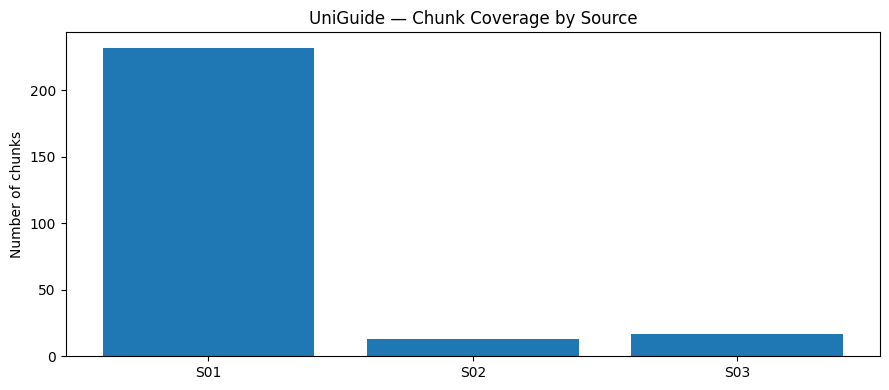

In [31]:
from collections import Counter
counts=Counter(c.metadata['source_id'] for c in unique_chunks)
coverage=pd.DataFrame([{'source':sid,'document':name,'chunks':counts[sid],'percent':100*counts[sid]/len(unique_chunks),'pages_represented':len({p['page'] for c in unique_chunks for p in [c.metadata]+c.metadata.get('duplicate_provenance',[]) if p['source_id']==sid}),'original_pages':page_counts[sid]} for sid,name in source_files.items()])
display(coverage)
plt.figure(figsize=(9,4)); plt.bar(coverage.source,coverage.chunks); plt.ylabel('Number of chunks'); plt.title('UniGuide — Chunk Coverage by Source'); plt.tight_layout(); plt.savefig(DOCS/'week4_coverage_by_source.png'); plt.show()

## B3 — Representation Coverage and Bias Assessment

### B3.1 Representation Coverage

After data cleaning, the UniGuide dataset contains 262 chunks distributed across three academic documents.

| Source | Cleaned Chunks | Percentage |
|---|---:|---:|
| S01 — Academic Regulations 2026 | 232 | 88.55% |
| S02 — Course Registration Guide 2026/2027 | 13 | 4.96% |
| S03 — Academic Calendar 2026/2027 | 17 | 6.49% |
| Total | 262 | 100% |

The dataset is dominated by academic regulations, while course registration guidelines and academic calendar information have considerably fewer chunks. This difference is partly caused by the original document lengths. However, it may also affect retrieval performance across different academic topics.

### B3.2 Identified Bias Risks

| Bias Type | Evidence | Potential Impact | Proposed Mitigation |
|---|---|---|---|
| Representation bias | Academic regulations account for 88.55% of the cleaned dataset. | Academic regulations may be overrepresented in retrieval results compared to other academic topics. | Evaluate retrieval separately for each document category and apply source-aware retrieval where necessary. |
| User coverage bias | The course registration guide specifically targets senior full-time undergraduate students. | New students or students with different study arrangements may receive unsuitable registration guidance. | Include additional official registration guidelines covering different student groups. |
| Measurement and processing bias | PDF extraction noise and incomplete sentences resulted in the exclusion of 23 chunks. | Relevant academic information may become unavailable, particularly when important regulations are fragmented. | Verify quarantined chunks against the original PDFs and improve sentence-aware chunking. |
| Knowledge coverage bias | Programme handbooks are within the intended project scope but are not represented in the current dataset. | Students asking programme-specific questions may receive incomplete answers. | Include approved programme handbooks and provide an insufficient-information response when supporting evidence is unavailable. |

### B3.3 Bias Propagation

**Risk 1 — Representation bias**

Unequal document lengths → Imbalanced chunk distribution → Potentially unequal retrieval opportunities → Students may receive less relevant answers for registration and calendar enquiries.

**Risk 2 — User coverage bias**

Registration guide targets senior full-time students → Limited representation of other student groups → Retrieval lacks applicable registration procedures → New students may receive unsuitable guidance.

**Risk 3 — Measurement and processing bias**

PDF extraction and sentence fragmentation → Relevant chunks are quarantined or removed → Reduced availability of academic information → Students may receive incomplete answers.

**Risk 4 — Knowledge coverage bias**

Missing programme handbooks → Programme-specific information is unavailable in the corpus → Relevant evidence cannot be retrieved → Students may not receive answers about their programme requirements.

### B3.4 Mitigation Plan

1. Expand the dataset using relevant official UTM academic documents.
2. Evaluate retrieval performance separately for each academic document category.
3. Verify quarantined chunks against their original PDF pages before restoring them.
4. Improve the chunking method to preserve complete sentences and academic regulations.
5. Implement an insufficient-information response when relevant supporting documents cannot be retrieved.
6. Maintain source metadata to support transparent and traceable answers.

### B3.5 Residual Risk

Although data cleaning improves dataset quality, it does not eliminate all representation and coverage limitations. Some academic topics and student groups remain underrepresented.

The unequal chunk distribution alone does not prove that retrieval bias exists. Further retrieval evaluation is required to determine its actual impact.

These limitations should be considered during subsequent system development and evaluation.

**Related Topic 2 requirements:** FR1, FR2, FR3, FR4, NFR2, RAI1 and RAI2.

## B4 — Responsible Data Practices

### B4.1 Privacy and Personal Information

UniGuide uses academic documents to provide general academic information to UTM undergraduate students. The system does not require access to individual student academic records, identification numbers or login credentials.

However, the course registration guide contains a sample registration slip on Page 9, which may contain personal information. The original page should be inspected before the dataset is approved for deployment.

Any unnecessary personal information identified should be removed or anonymised before being included in the retrieval dataset.

### B4.2 Consent, Copyright and Access Rights

The dataset consists of three academic documents associated with UTM.

| Source ID | Document | Intended Use | Access Rights Status |
|---|---|---|---|
| S01 | Academic Regulations 2026 | Academic regulations and policies | Pending verification |
| S02 | Course Registration Guide 2026/2027 | Course registration guidance | Pending verification |
| S03 | Academic Calendar 2026/2027 | Academic dates and schedules | Pending verification |

The documents are intended for educational and academic information retrieval purposes. However, public accessibility does not automatically grant permission to redistribute or reuse copyrighted materials.

Document access rights and permitted usage must be verified before public deployment or redistribution through GitHub.

The current project does not intentionally collect personal information directly from students. If personal information is identified in the source documents, appropriate permission or anonymisation must be considered.

### B4.3 Data Governance

| Governance Aspect | Proposed Practice |
|---|---|
| Source traceability | Maintain source IDs, document names and page numbers for every retained chunk. |
| Data integrity | Use SHA-256 hashing to verify data integrity and identify exact duplicates. |
| Version control | Record document versions, academic sessions and update history. |
| Data access | Restrict access to documents and datasets containing sensitive information. |
| Data cleaning | Maintain records of removed, retained and quarantined chunks. |
| Data retention | Preserve original documents securely for verification and future corrections. |
| Data updates | Reprocess and validate documents when updated official versions become available. |
| Data redistribution | Verify usage permissions before publishing raw documents or processed datasets. |

### B4.4 Responsible AI Risk Assessment

| Risk | Mitigation | Related Requirement |
|---|---|---|
| Exposure of student personal information | Inspect and anonymise sensitive information before deployment. | RAI3 |
| Incorrect academic information | Validate extracted text and verify suspicious chunks against original documents. | NFR2, RAI1 |
| Outdated academic policies | Verify document versions and maintain an update process. | NFR4, RAI1 |
| Unsupported academic answers | Provide an insufficient-information response when relevant evidence is unavailable. | FR4, RAI1, RAI2 |
| Unauthorised document redistribution | Verify copyright and access rights before publishing datasets. | Data governance |

### B4.5 Remaining Governance Limitations

The current dataset has undergone automated validation, manual triage and duplicate detection. However, document access rights, version currency and potential personal information still require further verification.

These limitations must be addressed before public deployment. UniGuide should support students in accessing academic information rather than replace official university departments or academic advisors.

**Related Topic 2 requirements:** FR3, FR4, NFR2, NFR4, RAI1, RAI2 and RAI3.

## C1 — Data Quality, Bias and Responsible Data Report
Create `docs/week4_data_quality_report.md` using these eight headings. Fill with measured results and verified evidence, not example numbers.
1. Data Quality Scorecard (five dimensions, rating 1–5 or N.V., evidence and action)
2. Validation and Data-Defect Findings (rule, denominator, failure count/percentage, triage)
3. Duplicate and Anomaly Findings
4. Representation, Coverage, and Bias Assessment (two risks)
5. Privacy, Consent, Rights/Access, and Data Governance
6. Mitigation Plan and Residual Risk (owner/timing)
7. Impact on Topic 2 Requirements / Evaluation Criteria
8. Topic 4 Quality Gate Decision (GO / GO WITH CONDITIONS / HOLD, reasons and follow-up)
Do not claim GO while critical rights or data issues are unresolved.

In [22]:
from pathlib import Path

report = """
# Topic 4 — Data Quality, Bias and Responsible Data Assessment Report

**Project:** UniGuide — An AI-Powered Academic Information Assistant for UTM Undergraduate Students

**Version:** 1.0

**Quality Gate Decision:** GO WITH CONDITIONS

## 1. Data Quality Scorecard

The purpose of this assessment is to evaluate the quality of the
prepared academic documents before proceeding to subsequent
AI system development activities.

The original dataset contained 285 chunks extracted from three
UTM academic documents. Following validation, manual review
and duplicate detection, 262 chunks were retained.

The following scores represent engineering judgement based
on the available evidence, using a scale of 1 to 5.
N.V. indicates that the dimension has not been fully verified.

| Quality Dimension | Score | Evidence | Recommended Action |
|---|---|---|---|
| Completeness | 3/5 | All three selected sources are represented, but programme handbooks are missing and some chunks were excluded. | Expand source coverage and review quarantined chunks. |
| Consistency | 4/5 | No hard structural validation failures were identified, but a potential calendar date inconsistency remains. | Verify dates and maintain consistent metadata. |
| Accuracy | 3/5 | Manual inspection identified extraction noise and incomplete academic statements. | Verify suspicious text against original PDFs. |
| Timeliness | N.V. | Document editions and academic sessions are identifiable, but their current official status has not been verified. | Confirm document versions with official UTM sources. |
| Uniqueness | 5/5 | No exact duplicate candidates were detected in the reviewed corpus using SHA-256 hashing. | Repeat duplicate checks after future updates. |

The dataset demonstrates good structural quality. However,
semantic accuracy, completeness and document currency
require further attention.

## 2. Validation and Data-Defect Findings

Pandera validation and additional profiling checks were used
to identify structural problems, missing information,
corrupted characters and suspiciously short text.

### 2.1 Validation Results

| Validation Check | Number of Affected Chunks |
|---|---:|
| Missing text | 0 |
| Missing source | 0 |
| Detected corrupted characters | 0 |
| Noisy whitespace | 0 |
| GID extraction errors | 0 |
| Hard validation failures | 0 |
| Short-text warnings | 26 |
| Additional suspicious OCR chunks | 2 |

The short-text threshold of 100 characters was used as a
warning condition rather than an automatic rejection rule.

A total of 26 chunks, representing 9.12% of the original
dataset, triggered the short-text warning.

Two additional chunks were flagged because manual inspection
identified suspicious OCR or extraction noise.

### 2.2 Manual Review and Triage

All 28 flagged chunks were manually reviewed.

| Decision | Number of Chunks |
|---|---:|
| Retain | 5 |
| Remove | 7 |
| Quarantine | 16 |
| Total | 28 |

Examples of reviewed cases are shown below.

| Chunk ID | Finding | Decision | Justification |
|---|---|---|---|
| 1 | Unreadable extracted text from the academic regulations cover page. | Quarantine | Requires verification against the original PDF. |
| 10 | Isolated contents heading and page number. | Remove | Contains no meaningful standalone academic information. |
| 150 | Incomplete statement concerning academic status and CGPA. | Quarantine | Missing context could result in misleading academic advice. |
| 251 | Significant extraction noise from the final page. | Quarantine | Text is unsuitable for reliable retrieval without verification. |
| 252 | Identifies the registration guide's intended audience. | Retain | Provides important information about the document's scope. |
| 260 | Instructions for viewing the course registration slip. | Retain | Short but meaningful academic guidance. |

The review demonstrates that short chunks are not necessarily
defective. Some contain useful information and should be
retained.

The detailed validation and triage evidence is recorded in:

- docs/week4_validation_failures.csv
- docs/week4_triage.csv

## 3. Duplicate and Anomaly Findings

Exact duplicate detection was performed using SHA-256 hashing
after normalising whitespace in the reviewed chunks.

| Processing Stage | Number of Chunks |
|---|---:|
| Original prepared dataset | 285 |
| After manual review | 262 |
| Exact duplicate candidates | 0 |
| After duplicate review | 262 |

A total of 23 chunks were excluded through manual review.
The cleaned dataset retains 91.93% of the original chunks.

No exact duplicate candidates were identified in the reviewed
corpus. However, this method does not detect all semantic
duplicates or differently worded repeated information.

Other identified anomalies include:

- OCR and PDF extraction noise.
- Incomplete sentence boundaries.
- Isolated headings and word fragments.
- A potential year inconsistency in the academic calendar.

The calendar inconsistency requires verification against
the original document before any correction is made.

Duplicate review evidence is stored in:

docs/week4_duplicate_review.csv

## 4. Representation Coverage and Bias Assessment

### 4.1 Source Coverage

| Source | Cleaned Chunks | Percentage | Pages Represented | Original Pages |
|---|---:|---:|---:|---:|
| Academic Regulations 2026 | 232 | 88.55% | 74 | 81 |
| Course Registration Guide 2026/2027 | 13 | 4.96% | 10 | 10 |
| Academic Calendar 2026/2027 | 17 | 6.49% | 2 | 2 |
| Total | 262 | 100% | 86 | 93 |

Academic regulations represent the largest proportion of the
dataset. This is partly explained by the original document
lengths.

Adequate coverage does not require equal chunk counts.
Instead, every supported academic task should have sufficient
authoritative evidence.

Page representation indicates that at least one chunk from
a page is present. It does not guarantee that all information
on that page has been preserved.

The coverage visualisation is stored in:

docs/week4_coverage_by_source.png

### 4.2 Identified Bias Risks and Propagation

| Bias Risk | Origin | Corpus Effect | Potential Retrieval Effect | Potential User Impact |
|---|---|---|---|---|
| Representation bias | Unequal source document lengths | Academic regulations dominate the corpus | Other topics may have fewer retrieval opportunities | Registration or calendar answers may be less relevant |
| User coverage bias | Registration guide targets senior full-time students | Other student groups are underrepresented | Applicable guidance may not be retrieved | New students may receive unsuitable guidance |
| Measurement and processing bias | PDF extraction and chunking decisions | Important academic statements may be fragmented or excluded | Supporting evidence may become unavailable | Students may receive incomplete academic answers |
| Knowledge coverage bias | Programme handbooks are absent | Programme-specific information is missing | Relevant programme evidence cannot be retrieved | Programme-specific questions may remain unanswered |

These are potential data-level bias risks. They do not prove
that the final retrieval or generation system is biased.

Further retrieval and answer evaluation will be required
during subsequent development activities.

## 5. Privacy, Consent, Rights and Data Governance

### 5.1 Privacy and Consent

UniGuide is designed to answer general academic enquiries.
It does not require access to individual student academic
records, identification numbers or login credentials.

The course registration guide contains a sample registration
slip on Page 9. This page requires further inspection to
determine whether unnecessary personal information is present.

Any identified personal information should be removed or
anonymised before the dataset is approved for deployment.

The project does not intentionally collect personal
information directly from students. Consent requirements
should be assessed according to the actual information
identified and its intended use.

### 5.2 Copyright and Access Rights

| Document | Intended Use | Access Rights Status |
|---|---|---|
| Academic Regulations 2026 | Academic regulations and policies | To be verified |
| Course Registration Guide 2026/2027 | Registration procedures | To be verified |
| Academic Calendar 2026/2027 | Academic dates and schedules | To be verified |

Public accessibility does not automatically grant permission
to redistribute copyrighted documents or their extracted
contents.

Access rights and permitted usage must be verified before
public deployment or redistribution through GitHub.

### 5.3 Data Governance Practices

| Governance Area | Practice |
|---|---|
| Traceability | Preserve source IDs, document names and page numbers. |
| Integrity | Use SHA-256 hashing for integrity and duplicate checks. |
| Version control | Record document versions and academic sessions. |
| Access control | Restrict access to sensitive or unapproved data. |
| Cleaning records | Preserve manual triage decisions and reasons. |
| Retention | Maintain original documents securely for verification. |
| Updates | Reprocess and validate updated official documents. |
| Redistribution | Publish only files that are authorised for sharing. |

## 6. Mitigation Plan and Residual Risk

| Identified Risk | Proposed Mitigation | Priority | Status |
|---|---|---|---|
| OCR and extraction noise | Verify suspicious chunks against original PDF pages. | High | Pending |
| Incomplete academic statements | Improve sentence-aware chunking and restore verified information. | High | Pending |
| Potential calendar inconsistency | Confirm dates against the official academic calendar. | High | Pending |
| Potential personal information | Inspect the sample registration slip and anonymise sensitive information if present. | High | Pending |
| Unverified access rights | Confirm permitted document usage and redistribution rights. | High | Pending |
| Unverified document currency | Confirm the latest applicable document editions. | High | Pending |
| Missing programme handbooks | Include relevant approved programme handbooks. | Medium | Pending |
| Unequal source representation | Evaluate retrieval separately across academic topics. | Medium | Planned |

### Residual Risk

Although the dataset has been structurally validated and
cleaned, important academic information may still be missing
or incomplete.

The exclusion of 16 quarantined chunks reduces exposure to
unreliable text but may also reduce information coverage.

Document currency, privacy and access rights remain
unverified. Therefore, the dataset should not be considered
fully approved for public deployment.

## 7. Impact on Topic 2 Requirements and Evaluation Criteria

The Topic 4 assessment supports the requirements defined
in the Topic 2 UniGuide Requirements Specification.

| Requirement | Topic 4 Contribution | Remaining Limitation |
|---|---|---|
| FR1 | Reviewed academic regulation content. | Programme handbooks are missing. |
| FR2 | Preserved registration and calendar sources. | Some registration information requires verification. |
| FR3 | Maintained source and page metadata. | Final citation correctness requires system testing. |
| FR4 | Identified knowledge gaps and unsupported areas. | Insufficient-information behaviour must be implemented and tested. |
| FR5 | Removed or quarantined unclear text. | Generated answer clarity remains untested. |
| NFR1 | Established a reviewed corpus for subsequent development. | Response latency has not been measured. |
| NFR2 | Reduced exposure to defective academic text. | Factual answer correctness requires evaluation. |
| NFR3 | Established repeatable validation procedures. | End-to-end reliability remains untested. |
| NFR4 | Preserved source metadata and repeatable processing. | Document update time has not been tested. |
| RAI1 | Improved traceability and identified misinformation risks. | Citation-source correctness requires evaluation. |
| RAI2 | Documented knowledge and user coverage limitations. | Refusal and redirection behaviour remains untested. |
| RAI3 | Identified potential privacy concerns. | Original document inspection and privacy testing remain necessary. |

### Topic 2 Evaluation Targets

| Requirement | Original Evaluation Target | Topic 4 Status |
|---|---|---|
| NFR1 | p90 response latency of 10 seconds or less | Not yet evaluated |
| NFR2 | Correct answer rate of at least 80% | Not yet evaluated |
| NFR3 | Successful query handling rate of at least 95% | Not yet evaluated |
| NFR4 | Document update time of 10 minutes or less | Not yet evaluated |
| RAI1 | Citation-source correctness rate of at least 95% | Not yet evaluated |
| RAI2 | Correct refusal and redirection rate of at least 95% | Not yet evaluated |
| RAI3 | Zero unnecessary personal information disclosures | Not yet evaluated |

Topic 4 provides dataset-level evidence supporting these
requirements. It does not demonstrate that the final
system-level evaluation targets have been achieved.

## 8. Topic 4 Quality Gate Decision

### Decision: GO WITH CONDITIONS

The UniGuide dataset is conditionally suitable for continued
controlled development and subsequent model selection.

This decision is supported by the following measured findings:

- 285 original chunks were assessed.
- No hard structural validation failures were identified.
- All 28 flagged chunks were manually reviewed.
- Seven chunks were removed.
- Sixteen chunks were quarantined.
- Five flagged chunks were retained.
- No exact duplicate candidates were detected.
- All three selected academic sources remain represented.
- A cleaned dataset containing 262 chunks was generated.

### Conditions

1. Verify quarantined academic information against the
   original PDF documents before restoring it.
2. Resolve the potential academic calendar date inconsistency.
3. Inspect the sample registration slip for personal information.
4. Verify document currency, access rights and permitted usage.
5. Expand programme-specific and student-group coverage
   before claiming full application scope.
6. Evaluate retrieval relevance, answer correctness, citation
   accuracy and responsible AI behaviour in later activities.

Public deployment and unauthorised dataset redistribution
must remain on hold until the relevant governance and
accuracy concerns have been resolved.

### Conclusion

The Topic 4 assessment established a reviewed and traceable
academic corpus for UniGuide. Automated validation,
manual inspection, duplicate detection and coverage analysis
provided evidence of the dataset's strengths and limitations.

The cleaned corpus can support subsequent controlled
development activities, subject to the identified conditions.

The assessment does not establish final system accuracy,
fairness, reliability or deployment readiness.
"""

docs_dir = Path("/content/week3_project/docs")
docs_dir.mkdir(parents=True, exist_ok=True)

report_path = docs_dir / "week4_data_quality_report.md"

report_path.write_text(report.strip(), encoding="utf-8")

print("Week 4 Data Quality Report successfully generated!")
print("Saved to:", report_path)
print("Word count:", len(report.split()))
print("File size:", report_path.stat().st_size, "bytes")

Week 4 Data Quality Report successfully generated!
Saved to: /content/week3_project/docs/week4_data_quality_report.md
Word count: 2230
File size: 14834 bytes


In [23]:
from google.colab import files

files.download(
    "/content/week3_project/docs/week4_data_quality_report.md"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## C2 — Verify exports and commit permitted artefacts

In [36]:
with (DATA/'chunks_clean.pkl').open('rb') as f: clean=pickle.load(f)
clean_json=[json.loads(s) for s in (DATA/'prepared_chunks_clean.jsonl').read_text(encoding='utf-8').splitlines()]
assert len(clean)==len(clean_json)
assert all(c.page_content==r['text'] and c.metadata==r['metadata'] for c,r in zip(clean,clean_json))
print('Clean corpus verified:',len(clean))
for p in [DOCS/'week4_validation_failures.csv',DOCS/'week4_duplicate_review.csv',DOCS/'week4_coverage_by_source.png',DOCS/'week4_data_quality_report.md']:
    print(p.name, 'FOUND' if p.is_file() else 'MISSING — complete before submission')

Clean corpus verified: 262
week4_validation_failures.csv FOUND
week4_duplicate_review.csv FOUND
week4_coverage_by_source.png FOUND
week4_data_quality_report.md FOUND


Save this notebook as `notebooks/week4_quality.ipynb`. Update README with report, quality gate, unresolved actions and the reviewed corpus path for Topic 7. Commit only authorised files; use approved restricted storage for anything not permitted to share. Verify online files. The notebook is a working template; manual decisions and report must be completed using actual results.

**Update the README file**

In [37]:
from pathlib import Path

project_dir = Path("/content/week3_project")
readme_path = project_dir / "README.md"

week4_summary = """
## Week 4 — Data Quality, Bias and Responsible Data Assessment

### Objective

Assess the quality, representation, reliability and responsible
use of the prepared academic dataset before proceeding to
subsequent AI system development activities.

### Activities Completed

- A0: Quality gate planning and requirements traceability.
- A1: Prepared dataset loading and integrity verification.
- A2: Data quality inventory and profiling.
- A3: Representative manual inspection.
- A4: Pandera schema and content validation.
- A5: Manual review and triage of flagged chunks.
- B1: SHA-256 exact duplicate detection.
- B2: Source representation and coverage analysis.
- B3: Bias assessment and mitigation planning.
- B4: Responsible data practices and governance assessment.
- C1: Data quality assessment report.
- C2: Deliverable verification and submission preparation.

### Data Quality Results

| Metric | Result |
|---|---:|
| Original chunks | 285 |
| Hard validation failures | 0 |
| Short-text warnings | 26 |
| Additional suspicious OCR chunks | 2 |
| Manually reviewed chunks | 28 |
| Retained flagged chunks | 5 |
| Removed chunks | 7 |
| Quarantined chunks | 16 |
| Exact duplicate candidates | 0 |
| Final cleaned chunks | 262 |
| Dataset retention rate | 91.93% |

### Cleaned Dataset Distribution

| Source | Chunks |
|---|---:|
| Academic Regulations 2026 | 232 |
| Course Registration Guide 2026/2027 | 13 |
| Academic Calendar 2026/2027 | 17 |

### Week 4 Deliverables

- notebooks/week4_quality.ipynb
- data/prepared_chunks_clean.jsonl
- data/chunks_clean.pkl
- docs/week4_data_quality_report.md
- docs/week4_validation_failures.csv
- docs/week4_duplicate_review.csv
- docs/week4_coverage_by_source.png
- docs/week4_triage.csv

### Quality Gate Decision

**GO WITH CONDITIONS**

The cleaned dataset is conditionally suitable for controlled
development. However, document accuracy, privacy, currency,
access rights and knowledge coverage require further verification.

Public deployment and unauthorised redistribution remain on hold.

### Next Steps

- Verify quarantined chunks against original documents.
- Improve sentence-aware chunking.
- Expand academic knowledge coverage.
- Verify document permissions and currency.
- Proceed with subsequent AI engineering activities.
- Evaluate retrieval and answer generation in later topics.
"""

existing_content = (
    readme_path.read_text(encoding="utf-8")
    if readme_path.exists()
    else "# UniGuide\n"
)

if "## Week 4 — Data Quality, Bias and Responsible Data Assessment" not in existing_content:
    with readme_path.open("a", encoding="utf-8") as f:
        f.write("\n\n" + week4_summary.strip() + "\n")

    print("README successfully updated!")
else:
    print("Week 4 section already exists.")

print("Saved to:", readme_path)

Week 4 section already exists.
Saved to: /content/week3_project/README.md


**Save the notebook inside project**

In [38]:
# C2 — Save Completed Week 4 Notebook

from google.colab import files
from pathlib import Path

notebooks_dir = Path("/content/week3_project/notebooks")
notebooks_dir.mkdir(parents=True, exist_ok=True)

uploaded = files.upload()

for filename, content in uploaded.items():
    if filename.endswith(".ipynb"):
        target = notebooks_dir / "week4_quality.ipynb"
        target.write_bytes(content)
        print("Successfully saved:", target)

Saving week4_quality (4).ipynb to week4_quality (4).ipynb
Successfully saved: /content/week3_project/notebooks/week4_quality.ipynb


**Verify all required deliverables**

In [39]:
from pathlib import Path

project_dir = Path("/content/week3_project")

required_files = [
    "notebooks/week4_quality.ipynb",
    "data/prepared_chunks_clean.jsonl",
    "data/chunks_clean.pkl",
    "docs/week4_data_quality_report.md",
    "docs/week4_validation_failures.csv",
    "docs/week4_duplicate_review.csv",
    "docs/week4_coverage_by_source.png",
    "docs/week4_triage.csv",
    "docs/week2_requirements.md",
    "README.md"
]

completed = 0

print("=" * 60)
print("WEEK 4 DELIVERABLE VERIFICATION")
print("=" * 60)

for filename in required_files:
    path = project_dir / filename

    if path.is_file() and path.stat().st_size > 0:
        print(f"[PASS] {filename}")
        completed += 1
    else:
        print(f"[MISSING OR EMPTY] {filename}")

print("=" * 60)
print(f"Files verified: {completed}/{len(required_files)}")

if completed == len(required_files):
    print("SUCCESS: All Week 4 deliverables are available.")
else:
    print("WARNING: Some deliverables are missing or empty.")

WEEK 4 DELIVERABLE VERIFICATION
[PASS] notebooks/week4_quality.ipynb
[PASS] data/prepared_chunks_clean.jsonl
[PASS] data/chunks_clean.pkl
[PASS] docs/week4_data_quality_report.md
[PASS] docs/week4_validation_failures.csv
[PASS] docs/week4_duplicate_review.csv
[PASS] docs/week4_coverage_by_source.png
[PASS] docs/week4_triage.csv
[PASS] docs/week2_requirements.md
[PASS] README.md
Files verified: 10/10
SUCCESS: All Week 4 deliverables are available.


**Download the final project backup**

In [40]:
# C2 — Export Final Week 4 Project Backup

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/UniGuide_Week4_Final",
    "zip",
    "/content/week3_project"
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>